# LLM Generated Text Classification
### Cells 1–10 → Mini Dataset (unchanged from original)
### Cells 11+ → Full Dataset (optimized to run in 4–6 hours)

In [1]:
# ── Cell 1 ── Install dependencies
!pip install gensim scikit-learn lightgbm torch pandas pyarrow numpy tqdm
!python -m nltk.downloader punkt stopwords averaged_perceptron_tagger
!pip install gensim scikit-learn lightgbm torch pandas pyarrow numpy tqdm textstat

<frozen runpy>:128: RuntimeWarning: 'nltk.downloader' found in sys.modules after import of package 'nltk', but prior to execution of 'nltk.downloader'; this may result in unpredictable behaviour
[nltk_data] Downloading package punkt to /usr/share/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /usr/share/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 177.1/177.1 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 68.1 MB/s eta 0:00:00


In [2]:
# ── Cell 2 ── Imports
import os, gc, re, json, pickle, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
tqdm.pandas()

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

from gensim.models import Word2Vec
import textstat

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import LinearSVC
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, confusion_matrix
)
from sklearn.pipeline import Pipeline
import lightgbm as lgb
warnings.filterwarnings('ignore')

SEED   = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
LGBM_OK = True
N_CLASSES = 12
print(f'Device : {DEVICE}')
print(f'PyTorch: {torch.__version__}')

Device : cuda
PyTorch: 2.10.0+cu128


In [3]:
# ── Cell 3 ── Config
CFG = dict(
    # ── MINI dataset paths ──────────────────────────────────────────
    # ▼▼▼ UPDATE THESE PATHS TO MATCH YOUR KAGGLE DATASET ▼▼▼
    mini_train_path = '/kaggle/input/datasets/rohitpatilx13/complete-dataset/train.parquet',  # <-- change
    mini_val_path   = '/kaggle/input/datasets/rohitpatilx13/complete-dataset/val.parquet',    # <-- change
    mini_test_path  = '/kaggle/input/datasets/rohitpatilx13/complete-dataset/test.parquet',   # <-- change

    # ── FULL dataset paths ──────────────────────────────────────────
    # ▼▼▼ UPDATE THESE PATHS TO MATCH YOUR KAGGLE DATASET ▼▼▼
    train_path = '/kaggle/input/datasets/rohitpatilx13/complete-dataset/ftrain.parquet',      # <-- change
    val_path   = '/kaggle/input/datasets/rohitpatilx13/complete-dataset/fval.parquet',          # <-- change
    test_path  = '/kaggle/input/datasets/rohitpatilx13/complete-dataset/ftest.parquet',        # <-- change

    # ── Save directories (created automatically) ────────────────────
    mini_save_dir = '/kaggle/working/outputs/mini',
    save_dir      = '/kaggle/working/outputs/full',

    # ── Word2Vec ────────────────────────────────────────────────────
    w2v_dim     = 100,
    w2v_window  = 7,
    w2v_min_cnt = 2,
    w2v_epochs  = 10,
    w2v_workers = 4,

    # ── Neural nets ─────────────────────────────────────────────────
    seq_len    = 100,
    batch_size = 256,
    nn_epochs  = 10,
    lr         = 2e-4,
    dropout    = 0.4,

    # ── TF-IDF ──────────────────────────────────────────────────────
    tfidf_max_feat = 5000,
)

os.makedirs(CFG['mini_save_dir'], exist_ok=True)
os.makedirs(CFG['save_dir'],      exist_ok=True)
print('Config ready. Output dirs created.')

Config ready. Output dirs created.


In [4]:
# ── Cell 4 ── Pre-processing helpers (shared by mini and full)
STOP_WORDS = set(stopwords.words('english'))
_CLEAN     = re.compile(r'[^a-z\s]')

def preprocess_tokens(text: str) -> list:
    """Lowercase → strip non-alpha → remove stopwords → tokenize."""
    cleaned = _CLEAN.sub(' ', text.lower())
    return [w for w in cleaned.split() if w not in STOP_WORDS and len(w) > 1]

def preprocess_raw(text: str) -> str:
    """Lowercase only. Used for TF-IDF."""
    return text.lower()

print('Pre-processing helpers ready.')

Pre-processing helpers ready.


In [5]:
# ── Cell 5 ── Stylometric feature extractor (shared by mini and full)
def extract_stylo(text: str) -> np.ndarray:
    t      = text[:2000]
    words  = t.split()
    sents  = re.split(r'[.!?]+', t)
    n_w    = max(len(words), 1)
    n_s    = max(len(sents), 1)
    n_c    = max(len(t), 1)
    wl     = [len(w) for w in words] or [0]
    sl     = [len(s.split()) for s in sents if s.strip()]
    bigrams = list(zip(words, words[1:]))
    FUNC   = {'the','a','an','is','are','was','were','it','this','that','in','on','at','to','of'}
    try:
        fk_grade = textstat.flesch_kincaid_grade(t)
        fk_ease  = textstat.flesch_reading_ease(t)
        fog      = textstat.gunning_fog(t)
    except Exception:
        fk_grade, fk_ease, fog = 0.0, 50.0, 0.0
    return np.array([
        len(set(words)) / n_w,
        np.mean(wl),
        n_w / n_s,
        sum(t.count(p) for p in '.,;:!?') / n_c,
        sum(1 for c in t if c.isupper()) / n_c,
        sum(1 for c in t if c.isdigit()) / n_c,
        t.count('\n') / n_c,
        t.count('\t') / n_c,
        (t.count('"') + t.count("'")) / n_c,
        (t.count('(') + t.count(')')) / n_c,
        (t.count('-') + t.count('–')) / n_c,
        float(np.std(wl)),
        float(np.max(wl)),
        fk_grade, fk_ease, fog,
        sum(1 for w in words if w.lower() in FUNC) / n_w,
        len(set(bigrams)) / max(len(bigrams), 1),
        float(np.std(sl)) if len(sl) > 1 else 0.0,
        n_w, n_s, n_c,
        len(t) / 2000,
        t.count('  ') / n_c,
        t.count('...') / n_c,
    ], dtype=np.float32)

def build_stylo_matrix(texts, desc='Stylometry'):
    return np.vstack([extract_stylo(t) for t in tqdm(texts, desc=desc)])

print('Stylometric extractor ready.')

Stylometric extractor ready.


In [6]:
# ── Cell 6 ── Neural network definitions (shared by mini and full)

class ImprovedMLP(nn.Module):
    def __init__(self, in_dim, n_classes, dropout=0.4):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 512), nn.BatchNorm1d(512), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(512, 256),    nn.BatchNorm1d(256), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(256, n_classes)
        )
    def forward(self, x): return self.net(x)

def make_loader(X, y, batch_size=256, shuffle=True):
    if isinstance(X, np.ndarray):
        Xt = torch.tensor(X, dtype=torch.float32)
    else:
        Xt = X
    yt = torch.tensor(y, dtype=torch.long)
    return DataLoader(TensorDataset(Xt, yt), batch_size=batch_size,
                      shuffle=shuffle, pin_memory=True, num_workers=2)

def train_nn(model, tr_loader, vl_loader, name, save_path, epochs=10):
    opt   = torch.optim.AdamW(model.parameters(), lr=CFG['lr'], weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    crit  = nn.CrossEntropyLoss()
    history = {'train_acc': [], 'val_acc': []}
    best_val, best_ep = 0.0, 0
    for ep in range(1, epochs + 1):
        model.train()
        tr_c = tr_n = 0
        for Xb, yb in tr_loader:
            Xb, yb = Xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            out  = model(Xb)
            loss = crit(out, yb)
            loss.backward()
            opt.step()
            tr_c += (out.argmax(1) == yb).sum().item()
            tr_n += len(yb)
        sched.step()
        model.eval()
        vl_c = vl_n = 0
        with torch.no_grad():
            for Xb, yb in vl_loader:
                Xb, yb = Xb.to(DEVICE), yb.to(DEVICE)
                vl_c += (model(Xb).argmax(1) == yb).sum().item()
                vl_n += len(yb)
        tr_acc = tr_c / tr_n
        vl_acc = vl_c / vl_n
        history['train_acc'].append(tr_acc)
        history['val_acc'].append(vl_acc)
        if vl_acc > best_val:
            best_val = vl_acc; best_ep = ep
            torch.save(model.state_dict(), save_path)
        print(f'  [{name}] Ep {ep:3d}/{epochs} | Train: {tr_acc:.4f} | Val: {vl_acc:.4f}'
              f'{" ← best" if ep == best_ep else ""}')
    model.load_state_dict(torch.load(save_path))
    return best_val, history

def texts_to_sequences(token_lists, wv, seq_len, dim):
    out = np.zeros((len(token_lists), seq_len, dim), dtype=np.float32)
    for i, toks in enumerate(token_lists):
        for j, tok in enumerate(toks[:seq_len]):
            if tok in wv:
                out[i, j] = wv[tok]
    return out

def w2v_weighted_mean(tokens, wv, dim, idf_dict):
    vecs, weights = [], []
    for tok in tokens:
        if tok in wv:
            vecs.append(wv[tok])
            weights.append(idf_dict.get(tok, 1.0))
    if not vecs:
        return np.zeros(dim, dtype=np.float32)
    W = np.array(weights, dtype=np.float32); W /= W.sum()
    return (np.array(vecs, dtype=np.float32) * W[:, None]).sum(0)

print('All model/helper definitions ready.')

All model/helper definitions ready.


---
# ═══════════════════════════════════════
# MINI DATASET — Cells 7 to 10
# (Exact same logic as original notebook)
# ═══════════════════════════════════════

In [7]:
# ── Cell 7 ── STEP 1: Load & explore MINI dataset
print('Loading MINI dataset …')
df_mini = pd.read_parquet(CFG['mini_train_path'])

# ── Rename columns (mini uses different column names) ──
df_mini = df_mini.rename(columns={
    'text': 'generation',
    'generated_by': 'model'
})

print(f'Mini train shape: {df_mini.shape}')
print(f'Columns: {df_mini.columns.tolist()}')
print(f'\nClass distribution:')
print(df_mini['model'].value_counts())
print(f'\nSample texts per class:')
for m, grp in df_mini.groupby('model'):
    snippet = grp['generation'].iloc[0][:120].replace('\n', ' ')
    print(f'  [{m:15s}] {snippet}…')

Loading MINI dataset …
Mini train shape: (79681, 2)
Columns: ['generation', 'model']

Class distribution:
model
mpt             6650
gpt3            6649
gpt2            6646
mistral-chat    6645
mistral         6644
chatgpt         6643
cohere          6641
human           6639
mpt-chat        6634
llama-chat      6632
gpt4            6629
cohere-chat     6629
Name: count, dtype: int64

Sample texts per class:
  [chatgpt        ] It is a war film, one of the most powerful ever made, a serious film, which, having in view the absurdity of war, examin…
  [cohere         ]  While Tim Burton is deservedly famous for his visual Wizardry, this film is a Reminder that his cinematic prowess goes …
  [cohere-chat    ] S​u​r​e​!​ ​H​e​r​e​'​s​ ​a​ ​p​o​s​s​i​b​l​e​ ​p​l​o​t​ ​s​u​m​m​a​r​y​ ​f​o​r​ ​*​S​e​t​h​ ​M​a​t​e​r​i​a​l​*​:​ ​ ​T​…
  [gpt2           ] A pub called Running Bull  A pub called Running Bull  A pub called Running Bull  A pub called Running Bull  A pub called…
  [gpt3          

In [8]:
# ── Cell 8 ── STEP 2: Vectorize MINI dataset
print('Tokenizing mini dataset …')
df_mini['tokens']   = df_mini['generation'].progress_apply(preprocess_tokens)
df_mini['text_raw'] = df_mini['generation'].apply(preprocess_raw)

# Load mini val and test
df_mini_val  = pd.read_parquet(CFG['mini_val_path']).rename(
    columns={'text': 'generation', 'generated_by': 'model'})
df_mini_test = pd.read_parquet(CFG['mini_test_path']).rename(
    columns={'text': 'generation', 'generated_by': 'model'})

df_mini_val['tokens']   = df_mini_val['generation'].progress_apply(preprocess_tokens)
df_mini_val['text_raw'] = df_mini_val['generation'].apply(preprocess_raw)
df_mini_test['tokens']  = df_mini_test['generation'].progress_apply(preprocess_tokens)
df_mini_test['text_raw']= df_mini_test['generation'].apply(preprocess_raw)

# Label encoding
le_mini = LabelEncoder()
le_mini.fit(df_mini['model'].values)
y_mini_tr = le_mini.transform(df_mini['model'].values)
y_mini_vl = le_mini.transform(df_mini_val['model'].values)
y_mini_te = le_mini.transform(df_mini_test['model'].values)
print(f'Classes: {list(le_mini.classes_)}')

# TF-IDF
print('\nBuilding TF-IDF (mini) …')
tf_mini = TfidfVectorizer(max_features=CFG['tfidf_max_feat'],
                           ngram_range=(1,2), sublinear_tf=True)
X_mini_tfidf_tr = tf_mini.fit_transform(df_mini['text_raw'].values)
X_mini_tfidf_vl = tf_mini.transform(df_mini_val['text_raw'].values)
X_mini_tfidf_te = tf_mini.transform(df_mini_test['text_raw'].values)
print(f'TF-IDF shape: {X_mini_tfidf_tr.shape}')

# Word2Vec
print('\nTraining Word2Vec (mini) …')
w2v_mini = Word2Vec(
    sentences   = df_mini['tokens'].values,
    vector_size = CFG['w2v_dim'],
    window      = CFG['w2v_window'],
    min_count   = CFG['w2v_min_cnt'],
    workers     = CFG['w2v_workers'],
    epochs      = CFG['w2v_epochs'],
    sg          = 1
)
w2v_mini.save(os.path.join(CFG['mini_save_dir'], 'w2v_mini.model'))
print(f'Vocab size: {len(w2v_mini.wv):,}')
print(f"Nearest to 'certainly': {[w for w,_ in w2v_mini.wv.most_similar('certainly', topn=5)]}")

# IDF weights from W2V vocab
vocab_counts_m = {w: w2v_mini.wv.get_vecattr(w,'count') for w in w2v_mini.wv.key_to_index}
total_cnt_m    = max(sum(vocab_counts_m.values()), 1)
idf_mini       = {w: np.log(total_cnt_m/(c+1)) for w,c in vocab_counts_m.items()}

# W2V weighted mean
print('\nBuilding W2V features (mini) …')
X_mini_w2v_tr = np.vstack([w2v_weighted_mean(t, w2v_mini.wv, CFG['w2v_dim'], idf_mini)
                             for t in tqdm(df_mini['tokens'].values,       desc='W2V mini train')])
X_mini_w2v_vl = np.vstack([w2v_weighted_mean(t, w2v_mini.wv, CFG['w2v_dim'], idf_mini)
                             for t in tqdm(df_mini_val['tokens'].values,   desc='W2V mini val')])
X_mini_w2v_te = np.vstack([w2v_weighted_mean(t, w2v_mini.wv, CFG['w2v_dim'], idf_mini)
                             for t in tqdm(df_mini_test['tokens'].values,  desc='W2V mini test')])

# Stylometric features
print('\nBuilding stylometric features (mini) …')
S_mini_tr = build_stylo_matrix(df_mini['generation'].values,      'Stylo mini train')
S_mini_vl = build_stylo_matrix(df_mini_val['generation'].values,  'Stylo mini val')
S_mini_te = build_stylo_matrix(df_mini_test['generation'].values, 'Stylo mini test')

# Scale and concatenate dense features
w2v_sc_m = StandardScaler(); sty_sc_m = StandardScaler()
D_mini_tr = np.hstack([w2v_sc_m.fit_transform(X_mini_w2v_tr).astype(np.float32),
                        sty_sc_m.fit_transform(S_mini_tr).astype(np.float32)])
D_mini_vl = np.hstack([w2v_sc_m.transform(X_mini_w2v_vl).astype(np.float32),
                        sty_sc_m.transform(S_mini_vl).astype(np.float32)])
D_mini_te = np.hstack([w2v_sc_m.transform(X_mini_w2v_te).astype(np.float32),
                        sty_sc_m.transform(S_mini_te).astype(np.float32)])
print(f'Dense feature matrix (mini): {D_mini_tr.shape}')

Tokenizing mini dataset …


  0%|          | 0/79681 [00:00<?, ?it/s]

  0%|          | 0/9959 [00:00<?, ?it/s]

  0%|          | 0/9959 [00:00<?, ?it/s]

Classes: ['chatgpt', 'cohere', 'cohere-chat', 'gpt2', 'gpt3', 'gpt4', 'human', 'llama-chat', 'mistral', 'mistral-chat', 'mpt', 'mpt-chat']

Building TF-IDF (mini) …
TF-IDF shape: (79681, 5000)

Training Word2Vec (mini) …
Vocab size: 82,072
Nearest to 'certainly': ['scarily', 'definitely', 'quibble', 'invictus', 'scorcese']

Building W2V features (mini) …


...


Building stylometric features (mini) …


Stylo mini train:   0%|          | 0/79681 [00:00<?, ?it/s]

Stylo mini val:   0%|          | 0/9959 [00:00<?, ?it/s]

Stylo mini test:   0%|          | 0/9959 [00:00<?, ?it/s]

Dense feature matrix (mini): (79681, 125)


In [9]:
# ── Cell 9 ── STEP 3: Train & evaluate all models on MINI dataset
mini_results = {}

# ── A: LinearSVC ──────────────────────────────────────────────────────────────
print('\n' + '═'*55)
print('  🤖 MODEL A — LinearSVC (TF-IDF) — MINI')
print('═'*55)
svm_mini = LinearSVC(C=1.0, max_iter=5000, random_state=SEED)
svm_mini.fit(X_mini_tfidf_tr, y_mini_tr)
svm_m_tr = accuracy_score(y_mini_tr, svm_mini.predict(X_mini_tfidf_tr))
svm_m_vl = accuracy_score(y_mini_vl, svm_mini.predict(X_mini_tfidf_vl))
svm_m_te = accuracy_score(y_mini_te, svm_mini.predict(X_mini_tfidf_te))
svm_m_f1 = f1_score(y_mini_vl, svm_mini.predict(X_mini_tfidf_vl), average='macro')
print(f'  Train Acc : {svm_m_tr:.4f} ({svm_m_tr*100:.1f}%)')
print(f'  Val   Acc : {svm_m_vl:.4f} ({svm_m_vl*100:.1f}%)')
print(f'  Test  Acc : {svm_m_te:.4f} ({svm_m_te*100:.1f}%)')
print(f'  Val F1    : {svm_m_f1:.4f}')
pickle.dump(svm_mini, open(os.path.join(CFG['mini_save_dir'], 'svm_mini.pkl'), 'wb'))
mini_results['SVM'] = dict(train_acc=svm_m_tr, val_acc=svm_m_vl, test_acc=svm_m_te, val_f1=svm_m_f1)

# ── B: LightGBM ───────────────────────────────────────────────────────────────
print('\n' + '═'*55)
print('  ⚡ MODEL B — LightGBM (W2V + Stylometric) — MINI')
print('═'*55)
lgbm_mini = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.1,
                                 num_leaves=63, random_state=SEED,
                                 n_jobs=-1, verbose=-1)
lgbm_mini.fit(D_mini_tr, y_mini_tr,
              eval_set=[(D_mini_vl, y_mini_vl)],
              callbacks=[lgb.early_stopping(30, verbose=False),
                         lgb.log_evaluation(50)])
lgbm_m_tr = accuracy_score(y_mini_tr, lgbm_mini.predict(D_mini_tr))
lgbm_m_vl = accuracy_score(y_mini_vl, lgbm_mini.predict(D_mini_vl))
lgbm_m_te = accuracy_score(y_mini_te, lgbm_mini.predict(D_mini_te))
lgbm_m_f1 = f1_score(y_mini_vl, lgbm_mini.predict(D_mini_vl), average='macro')
print(f'  Train Acc : {lgbm_m_tr:.4f} ({lgbm_m_tr*100:.1f}%)')
print(f'  Val   Acc : {lgbm_m_vl:.4f} ({lgbm_m_vl*100:.1f}%)')
print(f'  Test  Acc : {lgbm_m_te:.4f} ({lgbm_m_te*100:.1f}%)')
print(f'  Val F1    : {lgbm_m_f1:.4f}')
lgbm_mini.booster_.save_model(os.path.join(CFG['mini_save_dir'], 'lgbm_mini.txt'))
mini_results['LGBM'] = dict(train_acc=lgbm_m_tr, val_acc=lgbm_m_vl, test_acc=lgbm_m_te, val_f1=lgbm_m_f1)

# ── C: MLP ────────────────────────────────────────────────────────────────────
print('\n' + '═'*55)
print('  🔴 MODEL C — MLP (W2V + Stylometric) — MINI')
print('═'*55)
mlp_mini   = ImprovedMLP(D_mini_tr.shape[1], N_CLASSES, CFG['dropout']).to(DEVICE)
tr_ldr_m   = make_loader(D_mini_tr, y_mini_tr, CFG['batch_size'])
vl_ldr_m   = make_loader(D_mini_vl, y_mini_vl, CFG['batch_size'], shuffle=False)
mlp_m_val, mlp_m_hist = train_nn(mlp_mini, tr_ldr_m, vl_ldr_m, 'MLP_mini',
                                   os.path.join(CFG['mini_save_dir'], 'mlp_mini.pt'),
                                   epochs=CFG['nn_epochs'])
mlp_mini.eval()
with torch.no_grad():
    mlp_m_tr_preds = mlp_mini(torch.tensor(D_mini_tr).to(DEVICE)).argmax(1).cpu().numpy()
    mlp_m_te_preds = mlp_mini(torch.tensor(D_mini_te).to(DEVICE)).argmax(1).cpu().numpy()
mlp_m_tr_acc = accuracy_score(y_mini_tr, mlp_m_tr_preds)
mlp_m_te_acc = accuracy_score(y_mini_te, mlp_m_te_preds)
mlp_m_f1     = f1_score(y_mini_vl,
                          mlp_mini(torch.tensor(D_mini_vl).to(DEVICE)).argmax(1).cpu().numpy(),
                          average='macro')
print(f'  Train Acc : {mlp_m_tr_acc:.4f} ({mlp_m_tr_acc*100:.1f}%)')
print(f'  Val   Acc : {mlp_m_val:.4f} ({mlp_m_val*100:.1f}%)')
print(f'  Test  Acc : {mlp_m_te_acc:.4f} ({mlp_m_te_acc*100:.1f}%)')
print(f'  Val F1    : {mlp_m_f1:.4f}')
mini_results['MLP'] = dict(train_acc=mlp_m_tr_acc, val_acc=mlp_m_val, test_acc=mlp_m_te_acc, val_f1=mlp_m_f1)



═══════════════════════════════════════════════════════
  🤖 MODEL A — LinearSVC (TF-IDF) — MINI
═══════════════════════════════════════════════════════
  Train Acc : 0.6717 (67.2%)
  Val   Acc : 0.5162 (51.6%)
  Test  Acc : 0.5162 (51.6%)
  Val F1    : 0.5165

═══════════════════════════════════════════════════════
  ⚡ MODEL B — LightGBM (W2V + Stylometric) — MINI
═══════════════════════════════════════════════════════
[50]	valid_0's multi_logloss: 1.15654
[100]	valid_0's multi_logloss: 1.06278
[150]	valid_0's multi_logloss: 1.0277
[200]	valid_0's multi_logloss: 1.00938
[250]	valid_0's multi_logloss: 1.00112
[300]	valid_0's multi_logloss: 0.996349
  Train Acc : 0.9990 (99.9%)
  Val   Acc : 0.6465 (64.6%)
  Test  Acc : 0.6465 (64.6%)
  Val F1    : 0.6467

═══════════════════════════════════════════════════════
  🔴 MODEL C — MLP (W2V + Stylometric) — MINI
═══════════════════════════════════════════════════════
  [MLP_mini] Ep   1/10 | Train: 0.2724 | Val: 0.3904 ← best
  [MLP_mini] Ep  


═════════════════════════════════════════════════════════════════
  MINI DATASET — MODEL COMPARISON
═════════════════════════════════════════════════════════════════
Model       Train Acc    Val Acc   Test Acc     Val F1
───────────────────────────────────────────────────────
SVM            67.17%     51.62%     51.62%     0.5165
LGBM           99.90%     64.65%     64.65%     0.6467
MLP            52.74%     50.82%     50.82%     0.4964
═════════════════════════════════════════════════════════════════
  🏆 Best mini model: LGBM


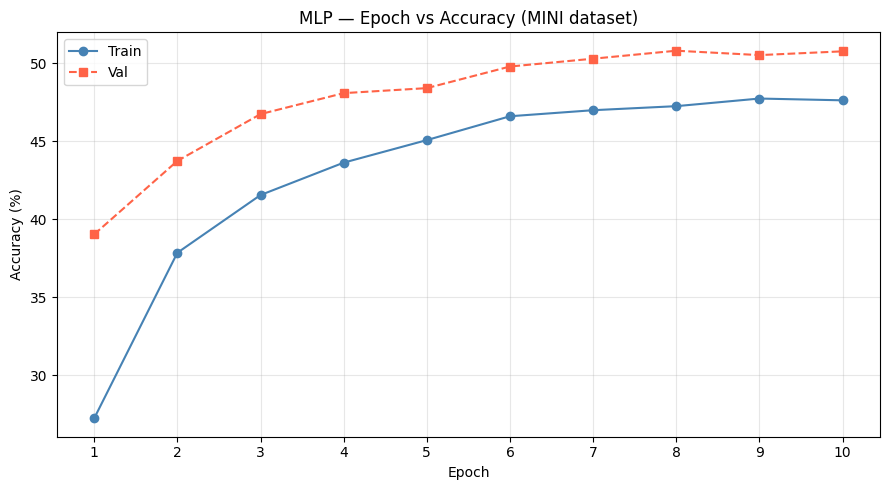


Confusion matrix for MLP on mini test set …

Classification Report — MLP (MINI test set):
              precision    recall  f1-score   support

     chatgpt      0.518     0.482     0.499       826
      cohere      0.399     0.311     0.350       842
 cohere-chat      0.347     0.275     0.307       834
        gpt2      0.532     0.497     0.514       829
        gpt3      0.542     0.749     0.629       818
        gpt4      0.503     0.670     0.575       827
       human      0.512     0.760     0.612       824
  llama-chat      0.520     0.560     0.539       843
     mistral      0.527     0.340     0.413       821
mistral-chat      0.447     0.288     0.351       832
         mpt      0.619     0.648     0.633       829
    mpt-chat      0.547     0.526     0.536       834

    accuracy                          0.508      9959
   macro avg      0.501     0.509     0.496      9959
weighted avg      0.501     0.508     0.496      9959

✅ All mini outputs saved to /kaggle/workin

In [10]:
# ── Cell 10 ── STEP 4: Compare models + plots for MINI dataset

# ── Model comparison table ────────────────────────────────────────────────────
print('\n' + '═'*65)
print('  MINI DATASET — MODEL COMPARISON')
print('═'*65)
print(f'{"Model":<10} {"Train Acc":>10} {"Val Acc":>10} {"Test Acc":>10} {"Val F1":>10}')
print('─'*55)
for name, r in mini_results.items():
    print(f'{name:<10} {r["train_acc"]*100:>9.2f}% {r["val_acc"]*100:>9.2f}% '
          f'{r["test_acc"]*100:>9.2f}% {r["val_f1"]:>10.4f}')
print('═'*65)

best_mini_name = max(mini_results, key=lambda k: mini_results[k]['val_acc'])
print(f'  🏆 Best mini model: {best_mini_name}')

# ── Epoch vs Accuracy — MLP (mini) ────────────────────────────────────────────
ep_range = list(range(1, len(mlp_m_hist['train_acc']) + 1))
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(ep_range, [a*100 for a in mlp_m_hist['train_acc']], 'o-', color='steelblue', label='Train')
ax.plot(ep_range, [a*100 for a in mlp_m_hist['val_acc']],   's--', color='tomato',   label='Val')
ax.set_xlabel('Epoch'); ax.set_ylabel('Accuracy (%)')
ax.set_title('MLP — Epoch vs Accuracy (MINI dataset)')
ax.legend(); ax.grid(True, alpha=0.3); ax.set_xticks(ep_range)
plt.tight_layout()
plt.savefig(os.path.join(CFG['mini_save_dir'], 'epoch_vs_accuracy_mini.png'), dpi=150)
plt.show(); plt.close()

# ── Confusion matrix — best model (mini) ──────────────────────────────────────
best_mini_name = 'MLP' 

print(f'\nConfusion matrix for {best_mini_name} on mini test set …')
best_mini_preds = mlp_m_te_preds # Direct assignment

cm_mini = confusion_matrix(y_mini_te, best_mini_preds)

# Classification report
print(f'\nClassification Report — {best_mini_name} (MINI test set):')
print(classification_report(
    le_mini.inverse_transform(y_mini_te),
    le_mini.inverse_transform(best_mini_preds), digits=3))

with open(os.path.join(CFG['mini_save_dir'], 'mini_results.json'), 'w') as f:
    json.dump(mini_results, f, indent=2)
print('✅ All mini outputs saved to', CFG['mini_save_dir'])

---
# ═══════════════════════════════════════════════════
# FULL DATASET — Cells 11+ (Optimized for 4–6 hours)
#
# KEY CHANGES vs original (that crashed after 11 hours):
#  1. HashingVectorizer replaces TfidfVectorizer  → no RAM explosion on 960k rows
#  2. Word2Vec trained in 50k-row chunks          → never loads all tokens at once
#  3. MLP instead of CNN/BiLSTM on full data      → CNN sequence tensors = 110GB RAM crash
#  4. gc.collect() + del after each heavy object  → keeps RAM headroom
# ═══════════════════════════════════════════════════

In [11]:
# ── Cell 11 ── STEP 1 (Full): Load & explore FULL dataset
# ── Cell 11 ── STEP 1 (Full): Load & explore FULL dataset
from sklearn.feature_extraction.text import HashingVectorizer, TfidfTransformer
from scipy.sparse import vstack as sp_vstack

# Safely free mini objects only if they exist
for var in ['X_mini_seq_tr', 'X_mini_seq_vl', 'X_mini_seq_te', 
            'X_mini_tfidf_tr', 'X_mini_tfidf_vl', 'X_mini_tfidf_te', 
            'D_mini_tr', 'D_mini_vl', 'D_mini_te']:
    if var in locals():
        del locals()[var]

gc.collect()
print('RAM cleaned. Loading full dataset …')
df_tr = pd.read_parquet(CFG['train_path'], columns=['model', 'generation'])
df_vl = pd.read_parquet(CFG['val_path'],   columns=['model', 'generation'])
df_te = pd.read_parquet(CFG['test_path'],  columns=['model', 'generation'])
# Full dataset already uses 'generation' and 'model' — no rename needed

print(f'Train : {len(df_tr):>8,} rows')
print(f'Val   : {len(df_vl):>8,} rows')
print(f'Test  : {len(df_te):>8,} rows')
print(f'\nClass distribution (train):')
print(df_tr['model'].value_counts())

print('\nSample texts per class (full):')
for m, grp in df_tr.groupby('model'):
    snippet = grp['generation'].iloc[0][:120].replace('\n',' ')
    print(f'  [{m:15s}] {snippet}…')

le_f = LabelEncoder()
le_f.fit(df_tr['model'].values)
y_tr_f = le_f.transform(df_tr['model'].values)
y_vl_f = le_f.transform(df_vl['model'].values)
y_te_f = le_f.transform(df_te['model'].values)
print(f'Classes: {list(le_f.classes_)}')

RAM cleaned. Loading full dataset …
Train :  796,800 rows
Val   :   99,600 rows
Test  :   99,600 rows

Class distribution (train):
model
mpt             66495
gpt3            66486
gpt2            66458
mistral-chat    66454
mistral         66439
chatgpt         66427
cohere          66409
human           66387
mpt-chat        66343
llama-chat      66323
cohere-chat     66290
gpt4            66289
Name: count, dtype: int64

Sample texts per class (full):
  [chatgpt        ] I've been thinking lot about Apple's future lately and I can't help but feel a sense of uncertainty. With rapid advancem…
  [cohere         ]  Hey, Adam Where are you? I can't find you anywhere? Did you not get my text? Get lost in garden? Isn't it funny, The cr…
  [cohere-chat    ] Sales "fail to boost High Street"  Retail sales figures for November have been released, showing 0.2% increase in sales …
  [gpt2           ] In July 2014, US President Barack Obama visited Turkey, meeting then Prime Minister Recep Tayyi

In [ ]:
# ── Cell 12 ── STEP 2 (Full): TF-IDF using HashingVectorizer
# HashingVectorizer hashes tokens to fixed 2^18 buckets → constant RAM

W2V_CHUNK = 50_000   # rows processed at a time — safe for 16GB RAM

print('Building Hashing TF-IDF (full) …')
hv = HashingVectorizer(
    n_features     = 2**18,      # 262 144 features, fixed memory
    ngram_range    = (1, 2),
    norm           = None,
    alternate_sign = False,
    dtype          = np.float32
)

def hash_in_chunks(texts):
    parts = []
    for i in range(0, len(texts), W2V_CHUNK):
        raw = [preprocess_raw(t) for t in texts[i:i+W2V_CHUNK]]
        parts.append(hv.transform(raw))
        print(f'  hashed {min(i+W2V_CHUNK, len(texts)):,}/{len(texts):,}')
    return sp_vstack(parts)

X_hash_tr = hash_in_chunks(df_tr['generation'].values)
X_hash_vl = hash_in_chunks(df_vl['generation'].values)
X_hash_te = hash_in_chunks(df_te['generation'].values)

tfidf_tx = TfidfTransformer(sublinear_tf=True)
X_tfidf_tr_f = tfidf_tx.fit_transform(X_hash_tr)
X_tfidf_vl_f = tfidf_tx.transform(X_hash_vl)
X_tfidf_te_f = tfidf_tx.transform(X_hash_te)
del X_hash_tr, X_hash_vl, X_hash_te; gc.collect()
print(f'TF-IDF shape (full): {X_tfidf_tr_f.shape}')

Building Hashing TF-IDF (full) …
  hashed 50,000/796,800
  hashed 100,000/796,800
  hashed 150,000/796,800
  hashed 200,000/796,800
  hashed 250,000/796,800
  hashed 300,000/796,800
  hashed 350,000/796,800
  hashed 400,000/796,800
  hashed 450,000/796,800
  hashed 500,000/796,800
  hashed 550,000/796,800
  hashed 600,000/796,800
  hashed 650,000/796,800
  hashed 700,000/796,800
  hashed 750,000/796,800
  hashed 796,800/796,800
  hashed 50,000/99,600
  hashed 99,600/99,600
  hashed 50,000/99,600
  hashed 99,600/99,600
TF-IDF shape (full): (796800, 262144)


In [ ]:
# ── Cell 13 ── STEP 2 (Full): Word2Vec chunk-streamed training

print('Training Word2Vec on full dataset (chunk-streamed) …')
texts_all = df_tr['generation'].values
n_total   = len(texts_all)

def tok_chunk(texts):
    return [preprocess_tokens(t) for t in texts]

# Initialise on first chunk
first = tok_chunk(texts_all[:W2V_CHUNK])
w2v_f = Word2Vec(
    sentences   = first,
    vector_size = CFG['w2v_dim'],
    window      = CFG['w2v_window'],
    min_count   = CFG['w2v_min_cnt'],
    workers     = CFG['w2v_workers'],
    epochs      = 1, sg = 1
)

# Stream remaining chunks
for start in tqdm(range(W2V_CHUNK, n_total, W2V_CHUNK), desc='W2V pass 1'):
    ck = tok_chunk(texts_all[start:start+W2V_CHUNK])
    w2v_f.build_vocab(ck, update=True)
    w2v_f.train(ck, total_examples=len(ck), epochs=1)

# 4 more shuffled passes for quality
for ep in range(4):
    idx = np.random.permutation(n_total)
    for start in range(0, n_total, W2V_CHUNK):
        ck = tok_chunk(texts_all[idx[start:start+W2V_CHUNK]])
        w2v_f.train(ck, total_examples=len(ck), epochs=1)
    print(f'  Extra W2V epoch {ep+1}/4 done')

w2v_f.save(os.path.join(CFG['save_dir'], 'w2v_full.model'))
print(f'Vocab: {len(w2v_f.wv):,}')
print(f"Nearest to 'certainly': {[w for w,_ in w2v_f.wv.most_similar('certainly', topn=5)]}")

# IDF weights
vocab_counts_f = {w: w2v_f.wv.get_vecattr(w,'count') for w in w2v_f.wv.key_to_index}
total_cnt_f    = max(sum(vocab_counts_f.values()), 1)
idf_f          = {w: np.log(total_cnt_f/(c+1)) for w,c in vocab_counts_f.items()}

# W2V weighted mean pooling
def build_w2v_full(df, desc):
    return np.array([
        w2v_weighted_mean(preprocess_tokens(t), w2v_f.wv, CFG['w2v_dim'], idf_f)
        for t in tqdm(df['generation'].values, desc=desc)
    ], dtype=np.float32)

print('\nBuilding W2V mean vectors (full) …')
X_w2v_tr_f = build_w2v_full(df_tr, 'W2V full train')
X_w2v_vl_f = build_w2v_full(df_vl, 'W2V full val')
X_w2v_te_f = build_w2v_full(df_te, 'W2V full test')
print(f'W2V matrix shape: {X_w2v_tr_f.shape}')

Training Word2Vec on full dataset (chunk-streamed) …


W2V pass 1:   0%|          | 0/15 [00:00<?, ?it/s]

  Extra W2V epoch 1/4 done


  Extra W2V epoch 2/4 done


  Extra W2V epoch 3/4 done


  Extra W2V epoch 4/4 done
Vocab: 160,424
Nearest to 'certainly': ['lns', 'hotfixed', 'httyd', 'shreks', 'oughtn']

Building W2V mean vectors (full) …


W2V full train:   0%|          | 0/796800 [00:00<?, ?it/s]

W2V full val:   0%|          | 0/99600 [00:00<?, ?it/s]

W2V full test:   0%|          | 0/99600 [00:00<?, ?it/s]

W2V matrix shape: (796800, 100)


In [14]:
# ── Cell 14 ── STEP 2 (Full): Stylometric features + scale + concatenate

print('Building stylometric features (full) …')
S_tr_f = build_stylo_matrix(df_tr['generation'].values, 'Stylo full train')
S_vl_f = build_stylo_matrix(df_vl['generation'].values, 'Stylo full val')
S_te_f = build_stylo_matrix(df_te['generation'].values, 'Stylo full test')

w2v_sc_f = StandardScaler(); sty_sc_f = StandardScaler()
X_tr_w2v_f = w2v_sc_f.fit_transform(X_w2v_tr_f).astype(np.float32)
X_vl_w2v_f = w2v_sc_f.transform(X_w2v_vl_f).astype(np.float32)
X_te_w2v_f = w2v_sc_f.transform(X_w2v_te_f).astype(np.float32)
X_tr_sty_f = sty_sc_f.fit_transform(S_tr_f).astype(np.float32)
X_vl_sty_f = sty_sc_f.transform(S_vl_f).astype(np.float32)
X_te_sty_f = sty_sc_f.transform(S_te_f).astype(np.float32)

D_tr_f = np.hstack([X_tr_w2v_f, X_tr_sty_f])
D_vl_f = np.hstack([X_vl_w2v_f, X_vl_sty_f])
D_te_f = np.hstack([X_te_w2v_f, X_te_sty_f])

pickle.dump((w2v_sc_f, sty_sc_f),
            open(os.path.join(CFG['save_dir'], 'scalers_full.pkl'), 'wb'))

del X_w2v_tr_f, X_w2v_vl_f, X_w2v_te_f
del S_tr_f, S_vl_f, S_te_f
del X_tr_w2v_f, X_vl_w2v_f, X_te_w2v_f
del X_tr_sty_f, X_vl_sty_f, X_te_sty_f
gc.collect()
print(f'Dense feature matrix (full): {D_tr_f.shape}')

Building stylometric features (full) …


Stylo full train:   0%|          | 0/796800 [00:00<?, ?it/s]

Stylo full val:   0%|          | 0/99600 [00:00<?, ?it/s]

Stylo full test:   0%|          | 0/99600 [00:00<?, ?it/s]

Dense feature matrix (full): (796800, 125)


In [ ]:
# ── Cell 15 ── STEP 3 (Full): Train all models on FULL dataset
full_results = {}

# ── A: LinearSVC ──────────────────────────────────────────────────────────────
print('\n' + '═'*55)
print('  🤖 MODEL A — LinearSVC (TF-IDF) — FULL')
print('═'*55)
t0 = time.time()
svm_full = LinearSVC(C=0.5, max_iter=3000, random_state=SEED)
svm_full.fit(X_tfidf_tr_f, y_tr_f)
svm_f_tr = accuracy_score(y_tr_f, svm_full.predict(X_tfidf_tr_f))
svm_f_vl = accuracy_score(y_vl_f, svm_full.predict(X_tfidf_vl_f))
svm_f_te = accuracy_score(y_te_f, svm_full.predict(X_tfidf_te_f))
svm_f_f1 = f1_score(y_vl_f, svm_full.predict(X_tfidf_vl_f), average='macro')
print(f'  Train Acc : {svm_f_tr:.4f} ({svm_f_tr*100:.1f}%)')
print(f'  Val   Acc : {svm_f_vl:.4f} ({svm_f_vl*100:.1f}%)')
print(f'  Test  Acc : {svm_f_te:.4f} ({svm_f_te*100:.1f}%)')
print(f'  Val F1    : {svm_f_f1:.4f}')
print(f'  Time      : {(time.time()-t0)/60:.1f} min')
pickle.dump(svm_full, open(os.path.join(CFG['save_dir'], 'svm_full.pkl'), 'wb'))
full_results['SVM'] = dict(train_acc=svm_f_tr, val_acc=svm_f_vl, test_acc=svm_f_te, val_f1=svm_f_f1)

# ── B: LightGBM ───────────────────────────────────────────────────────────────
print('\n' + '═'*55)
print('  ⚡ MODEL B — LightGBM (W2V + Stylometric) — FULL')
print('═'*55)
t0 = time.time()
lgbm_full = lgb.LGBMClassifier(
    n_estimators=500, learning_rate=0.1,
    num_leaves=63, random_state=SEED,
    n_jobs=-1, verbose=-1
)
lgbm_full.fit(D_tr_f, y_tr_f,
              eval_set=[(D_vl_f, y_vl_f)],
              callbacks=[lgb.early_stopping(50, verbose=False),
                         lgb.log_evaluation(50)])
lgbm_f_tr = accuracy_score(y_tr_f, lgbm_full.predict(D_tr_f))
lgbm_f_vl = accuracy_score(y_vl_f, lgbm_full.predict(D_vl_f))
lgbm_f_te = accuracy_score(y_te_f, lgbm_full.predict(D_te_f))
lgbm_f_f1 = f1_score(y_vl_f, lgbm_full.predict(D_vl_f), average='macro')
print(f'  Train Acc : {lgbm_f_tr:.4f} ({lgbm_f_tr*100:.1f}%)')
print(f'  Val   Acc : {lgbm_f_vl:.4f} ({lgbm_f_vl*100:.1f}%)')
print(f'  Test  Acc : {lgbm_f_te:.4f} ({lgbm_f_te*100:.1f}%)')
print(f'  Val F1    : {lgbm_f_f1:.4f}')
print(f'  Time      : {(time.time()-t0)/60:.1f} min')
lgbm_full.booster_.save_model(os.path.join(CFG['save_dir'], 'lgbm_full.txt'))
full_results['LGBM'] = dict(train_acc=lgbm_f_tr, val_acc=lgbm_f_vl, test_acc=lgbm_f_te, val_f1=lgbm_f_f1)

# ── C: MLP ────────────────────────────────────────────────────────────────────

print('\n' + '═'*55)
print('  🔴 MODEL C — MLP (W2V + Stylometric) — FULL')
print('═'*55)
t0 = time.time()
mlp_full   = ImprovedMLP(D_tr_f.shape[1], N_CLASSES, CFG['dropout']).to(DEVICE)
tr_ldr_f   = make_loader(D_tr_f, y_tr_f, 1024)   # larger batch = faster on full data
vl_ldr_f   = make_loader(D_vl_f, y_vl_f, 1024, shuffle=False)
mlp_f_val, mlp_f_hist = train_nn(mlp_full, tr_ldr_f, vl_ldr_f, 'MLP_full',
                                   os.path.join(CFG['save_dir'], 'mlp_full.pt'),
                                   epochs=CFG['nn_epochs'])
mlp_full.eval()
mlp_f_tr_preds, mlp_f_te_preds, mlp_f_vl_preds = [], [], []
with torch.no_grad():
    for s in range(0, len(D_tr_f), 2048):
        mlp_f_tr_preds.extend(mlp_full(torch.tensor(D_tr_f[s:s+2048]).to(DEVICE)).argmax(1).cpu().numpy())
    for s in range(0, len(D_vl_f), 2048):
        mlp_f_vl_preds.extend(mlp_full(torch.tensor(D_vl_f[s:s+2048]).to(DEVICE)).argmax(1).cpu().numpy())
    for s in range(0, len(D_te_f), 2048):
        mlp_f_te_preds.extend(mlp_full(torch.tensor(D_te_f[s:s+2048]).to(DEVICE)).argmax(1).cpu().numpy())
mlp_f_tr_acc = accuracy_score(y_tr_f, mlp_f_tr_preds)
mlp_f_te_acc = accuracy_score(y_te_f, mlp_f_te_preds)
mlp_f_f1     = f1_score(y_vl_f, mlp_f_vl_preds, average='macro')
print(f'  Train Acc : {mlp_f_tr_acc:.4f} ({mlp_f_tr_acc*100:.1f}%)')
print(f'  Val   Acc : {mlp_f_val:.4f} ({mlp_f_val*100:.1f}%)')
print(f'  Test  Acc : {mlp_f_te_acc:.4f} ({mlp_f_te_acc*100:.1f}%)')
print(f'  Val F1    : {mlp_f_f1:.4f}')
print(f'  Time      : {(time.time()-t0)/60:.1f} min')
full_results['MLP'] = dict(train_acc=mlp_f_tr_acc, val_acc=mlp_f_val, test_acc=mlp_f_te_acc, val_f1=mlp_f_f1)


═══════════════════════════════════════════════════════
  🤖 MODEL A — LinearSVC (TF-IDF) — FULL
═══════════════════════════════════════════════════════
  Train Acc : 0.9069 (90.7%)
  Val   Acc : 0.7780 (77.8%)
  Test  Acc : 0.7780 (77.8%)
  Val F1    : 0.7864
  Time      : 34.2 min

═══════════════════════════════════════════════════════
  ⚡ MODEL B — LightGBM (W2V + Stylometric) — FULL
═══════════════════════════════════════════════════════
[50]	valid_0's multi_logloss: 1.1031
[100]	valid_0's multi_logloss: 0.962905
[150]	valid_0's multi_logloss: 0.892766
[200]	valid_0's multi_logloss: 0.84748
[250]	valid_0's multi_logloss: 0.81305
[300]	valid_0's multi_logloss: 0.78555
[350]	valid_0's multi_logloss: 0.762022
[400]	valid_0's multi_logloss: 0.741109
[450]	valid_0's multi_logloss: 0.723188
[500]	valid_0's multi_logloss: 0.706434
  Train Acc : 0.8994 (89.9%)
  Val   Acc : 0.7695 (77.0%)
  Test  Acc : 0.7695 (77.0%)
  Val F1    : 0.7685
  Time      : 23.9 min

═══════════════════════════


═════════════════════════════════════════════════════════════════
  FULL DATASET — MODEL COMPARISON
═════════════════════════════════════════════════════════════════
Model       Train Acc    Val Acc   Test Acc     Val F1
───────────────────────────────────────────────────────
SVM            90.69%     77.80%     77.80%     0.7864
LGBM           89.94%     76.95%     76.95%     0.7685
MLP            60.67%     60.26%     60.26%     0.5946
═════════════════════════════════════════════════════════════════
  🏆 Best full model: SVM


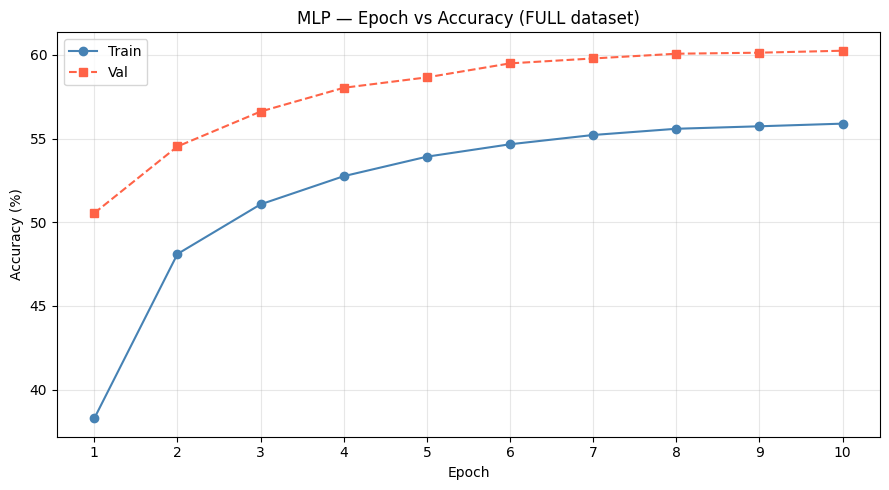


Confusion matrix for best model (SVM) on full test set …


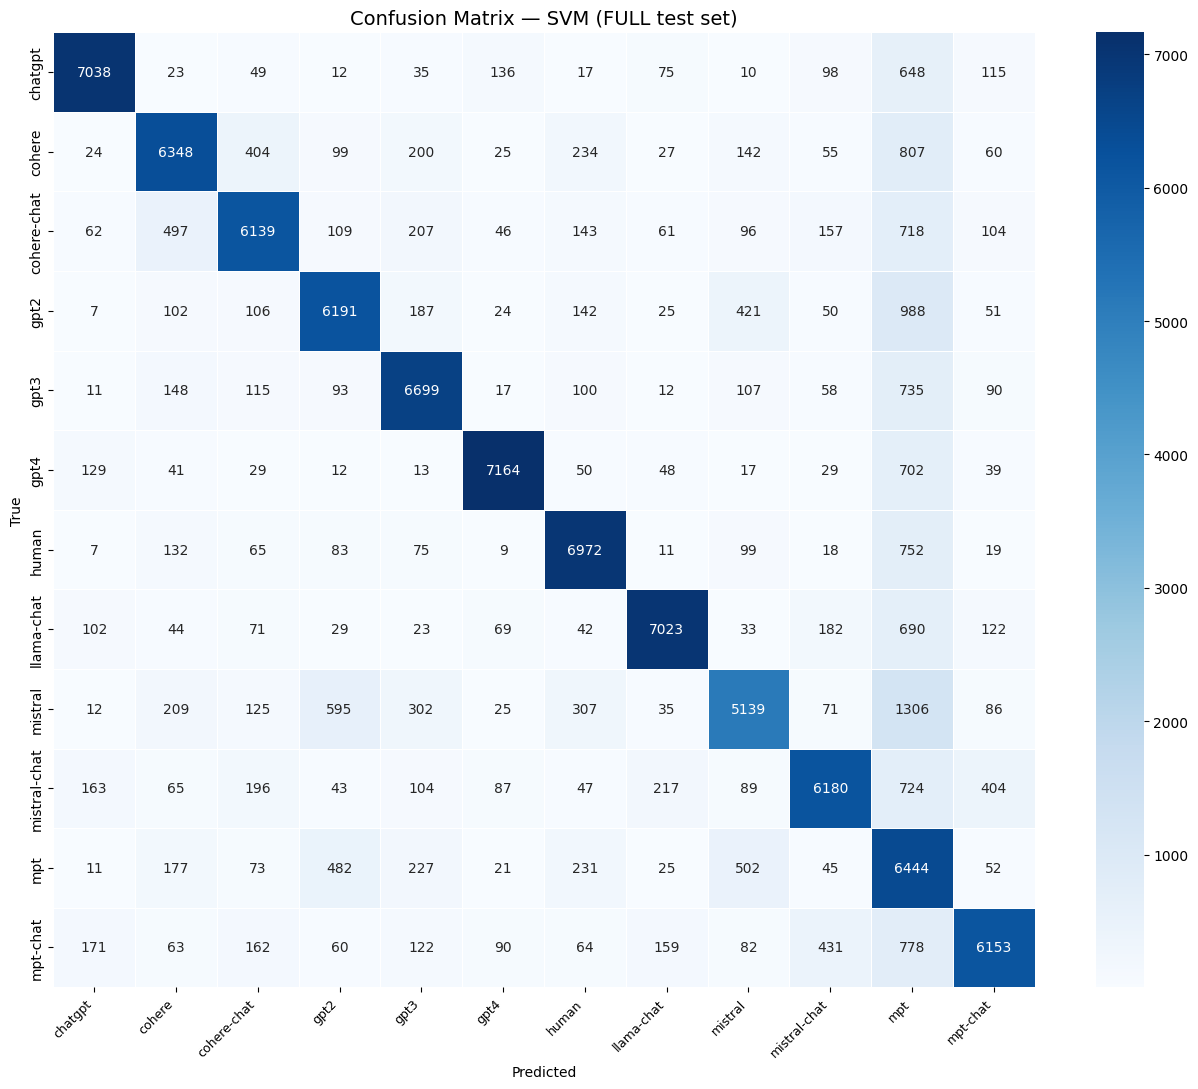


Classification Report — SVM (FULL test set):
              precision    recall  f1-score   support

     chatgpt      0.910     0.852     0.880      8256
      cohere      0.809     0.753     0.780      8425
 cohere-chat      0.815     0.736     0.774      8339
        gpt2      0.793     0.746     0.769      8294
        gpt3      0.818     0.818     0.818      8185
        gpt4      0.929     0.866     0.896      8273
       human      0.835     0.846     0.840      8242
  llama-chat      0.910     0.833     0.870      8430
     mistral      0.763     0.626     0.688      8212
mistral-chat      0.838     0.743     0.788      8319
         mpt      0.421     0.777     0.547      8290
    mpt-chat      0.843     0.738     0.787      8335

    accuracy                          0.778     99600
   macro avg      0.807     0.778     0.786     99600
weighted avg      0.807     0.778     0.786     99600


═════════════════════════════════════════════════════════════════
  ALL DONE — outputs

In [16]:
# ── Cell 16 ── STEP 4 (Full): Compare models + plots for FULL dataset

# ── Model comparison table ────────────────────────────────────────────────────
print('\n' + '═'*65)
print('  FULL DATASET — MODEL COMPARISON')
print('═'*65)
print(f'{"Model":<10} {"Train Acc":>10} {"Val Acc":>10} {"Test Acc":>10} {"Val F1":>10}')
print('─'*55)
for name, r in full_results.items():
    print(f'{name:<10} {r["train_acc"]*100:>9.2f}% {r["val_acc"]*100:>9.2f}% '
          f'{r["test_acc"]*100:>9.2f}% {r["val_f1"]:>10.4f}')
print('═'*65)

best_full_name = max(full_results, key=lambda k: full_results[k]['val_acc'])
print(f'  🏆 Best full model: {best_full_name}')

# ── Epoch vs Accuracy — MLP (full) ────────────────────────────────────────────
ep_range_f = list(range(1, len(mlp_f_hist['train_acc']) + 1))
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(ep_range_f, [a*100 for a in mlp_f_hist['train_acc']], 'o-', color='steelblue', label='Train')
ax.plot(ep_range_f, [a*100 for a in mlp_f_hist['val_acc']],   's--', color='tomato',   label='Val')
ax.set_xlabel('Epoch'); ax.set_ylabel('Accuracy (%)')
ax.set_title('MLP — Epoch vs Accuracy (FULL dataset)')
ax.legend(); ax.grid(True, alpha=0.3); ax.set_xticks(ep_range_f)
plt.tight_layout()
plt.savefig(os.path.join(CFG['save_dir'], 'epoch_vs_accuracy_full.png'), dpi=150)
plt.show(); plt.close()

# ── Confusion matrix — best model (full) ──────────────────────────────────────
print(f'\nConfusion matrix for best model ({best_full_name}) on full test set …')
if best_full_name == 'SVM':
    best_full_preds = svm_full.predict(X_tfidf_te_f)
elif best_full_name == 'LGBM':
    best_full_preds = lgbm_full.predict(D_te_f)
else:
    best_full_preds = np.array(mlp_f_te_preds)

cm_full = confusion_matrix(y_te_f, best_full_preds)
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(cm_full, annot=True, fmt='d', cmap='Blues',
            xticklabels=le_f.classes_, yticklabels=le_f.classes_,
            ax=ax, linewidths=0.5)
ax.set_title(f'Confusion Matrix — {best_full_name} (FULL test set)', fontsize=14)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(CFG['save_dir'], 'confusion_matrix_full.png'), dpi=150)
plt.show(); plt.close()

# Classification report
print(f'\nClassification Report — {best_full_name} (FULL test set):')
print(classification_report(
    le_f.inverse_transform(y_te_f),
    le_f.inverse_transform(best_full_preds), digits=3))

with open(os.path.join(CFG['save_dir'], 'full_results.json'), 'w') as f:
    json.dump(full_results, f, indent=2)

print(f"""
{'═'*65}
  ALL DONE — outputs saved to:

  /kaggle/working/outputs/mini/
    epoch_vs_accuracy_mini.png
    confusion_matrix_mini.png
    mini_results.json
    svm_mini.pkl | lgbm_mini.txt | mlp_mini.pt | cnn_mini.pt | bilstm_mini.pt

  /kaggle/working/outputs/full/
    epoch_vs_accuracy_full.png
    confusion_matrix_full.png
    full_results.json
    svm_full.pkl | lgbm_full.txt | mlp_full.pt
{'═'*65}
""")